# Pipeline mimiSBM — descripteur par descripteur

Ce notebook a pour étapes : (`import` → `chargement des matrices d'adjacence` → `assemblage du tenseur A` → `estimation mimiSBM`) en utilisant la classe `MimiSBM` fournie.

**Différence avec `mimisbm_pipeline.ipynb` (version familles) :** chaque "vue" du tenseur `A` correspond ici à un **descripteur unique** (`Ka`, `TE_Coverage_Mean`, ...) et non plus à une famille regroupant plusieurs colonnes. La structure du pipeline est identique à la version familles, seule la liste des vues change.

**Différences importantes avec la version R:**
- La classe Python ne gère que le cas **symétrique** (`SBM_sym`), pas `SBM` dirigé ni `LBM` biparti.
- Elle ne prend **qu'un seul couple (K, Q)** par appel — pas de recherche automatique sur plusieurs valeurs comme dans certaines variantes R.
- Il n'y a pas de paramètre `n_init` intégré : on reproduit ce comportement en relançant `fit()` manuellement plusieurs fois avec des `random_state` différents et en gardant le run au meilleur ELBO (exactement le rôle que jouait `n_init=10` côté R).
- Le critère de sélection de modèle est l'**ELBO** (pas d'ICL calculé nativement ici).

Dépendances nécessaires : `numpy`, `pandas`, `scipy`, `scikit-learn`, `fastkmeanspp`.
```
pip install numpy pandas scipy scikit-learn fastkmeanspp
```


## Imports

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt

# Importation de la classe MimiSBM depuis le fichier mimisbm-main/mimisbm/_model.py
from mimisbm_main.mimisbm._base import MimiSBM


## 1. Chargement des données

In [2]:
data_dir = Path(r"/mnt/c/Users/thoma/OneDrive/Documents/ENSIIE/Master/Stage 3A/Données")
python_adj_dir = data_dir / "adjacency" / "lda"
plots_dir = Path(r"/mnt/c/Users/thoma/OneDrive/Documents/ENSIIE/Master/Stage 3A/Plots")
plots_dir.mkdir(parents=True, exist_ok=True)


## 2. Chargement des matrices d'adjacence

In [3]:
# Un descripteur = une vue du tenseur (au lieu d'une famille regroupant plusieurs colonnes)
descriptor_names = [
    "Ka",
    "PPI_Jaccard",
    "TE_Coverage_Asymmetry",
    "TE_Number_Asymmetry",
    "TE_Density_Asymmetry",
]

adj_dict = {}
for desc in descriptor_names:
    path = python_adj_dir / f"adjacency_matrix_silh_{desc}.csv"
    # index_col=0 retire la colonne d'index (equivalent au skip=1 + [, -1] du code R)
    adj = pd.read_csv(path, index_col=0).values

    unique_vals = np.unique(adj)
    print(f"[{desc}] Shape: {adj.shape[0]}x{adj.shape[1]}, "
          f"valeurs uniques: {sorted(unique_vals.tolist())}")

    if not np.all(np.isin(adj, [0, 1])):
        raise ValueError(f"Erreur : {desc} contient des valeurs differentes de 0 et 1")

    adj_dict[desc] = adj.astype(np.int64)


[Ka] Shape: 444x444, valeurs uniques: [0, 1]
[PPI_Jaccard] Shape: 444x444, valeurs uniques: [0, 1]
[TE_Coverage_Asymmetry] Shape: 444x444, valeurs uniques: [0, 1]
[TE_Number_Asymmetry] Shape: 444x444, valeurs uniques: [0, 1]
[TE_Density_Asymmetry] Shape: 444x444, valeurs uniques: [0, 1]


## 3. Assemblage et vérifications du tenseur A (N x N x V)

Diagonale mise à 0, symétrisation de sécurité si besoin,
puis vérifications (carré, dimensions cohérentes, symétrie, diagonale nulle).


In [4]:
N = adj_dict[descriptor_names[0]].shape[0]
V = len(descriptor_names)

assert all(adj_dict[desc].shape[0] == N for desc in descriptor_names)
assert all(adj_dict[desc].shape[1] == N for desc in descriptor_names)

A = np.zeros((N, N, V), dtype=np.int64)
for i, desc in enumerate(descriptor_names):
    adj = adj_dict[desc].copy()
    np.fill_diagonal(adj, 0)  # pas d'auto-boucle
    if not np.array_equal(adj, adj.T):
        adj = np.maximum(adj, adj.T)  # symetrisation de securite
    A[:, :, i] = adj

assert A.shape == (N, N, V)
assert all(np.array_equal(A[:, :, v], A[:, :, v].T) for v in range(V))
assert all(np.all(np.diag(A[:, :, v]) == 0) for v in range(V))

tensor_path = plots_dir / "adjacency_tensor_silh.npy"
np.save(tensor_path, A)
print(f"Tenseur A sauvegarde : {tensor_path}")


Tenseur A sauvegarde : /mnt/c/Users/thoma/OneDrive/Documents/ENSIIE/Master/Stage 3A/Plots/adjacency_tensor_silh.npy


## 4. Estimation mimiSBM (multi-run, équivalent de `n_init = 10` en R)

La classe Python n'a pas de paramètre `n_init` intégré (contrairement à la fonction
R `mimiSBM()`). On reproduit donc plusieurs initialisations aléatoires indépendantes, on garde le run qui atteint le meilleur ELBO.

In [5]:
K_set = 2  # nombre de clusters d'individus a tester
Q_set = 2  # nombre de composantes de vues a tester
N_INIT = 10

best_model = None
best_elbo = -np.inf

for run in range(1, N_INIT + 1):
    model = MimiSBM(
        n_clusters=K_set,
        n_components=Q_set,
        clusters_prior="jeffreys",
        components_prior="jeffreys",
        adjacency_prior="jeffreys",
        max_iter=100,
        tol=1e-4,
        random_state=run,  # graine differente a chaque run, comme les 10 runs R
    )
    model.fit(A)
    print(f"------------ Run {run} ------------")
    print(f"Evidence Lower Bound: {model.elbo_:.2f}  (converged={model.converged_})")

    if model.elbo_ > best_elbo:
        best_elbo = model.elbo_
        best_model = model

print()
print(f"Meilleur run retenu : ELBO = {best_elbo:.2f}")


------------ Run 1 ------------
Evidence Lower Bound: -235108.28  (converged=True)
------------ Run 2 ------------
Evidence Lower Bound: -235108.28  (converged=True)
------------ Run 3 ------------
Evidence Lower Bound: -235108.28  (converged=True)
------------ Run 4 ------------
Evidence Lower Bound: -235108.28  (converged=True)
------------ Run 5 ------------
Evidence Lower Bound: -235108.28  (converged=True)
------------ Run 6 ------------
Evidence Lower Bound: -235108.28  (converged=True)
------------ Run 7 ------------
Evidence Lower Bound: -235108.28  (converged=True)
------------ Run 8 ------------
Evidence Lower Bound: -235108.28  (converged=True)
------------ Run 9 ------------
Evidence Lower Bound: -235108.28  (converged=True)
------------ Run 10 ------------
Evidence Lower Bound: -235108.28  (converged=True)

Meilleur run retenu : ELBO = -235108.28


In [6]:
K_set = 2  # nombre de clusters d'individus a tester
Q_set = 2  # nombre de composantes de vues a tester
N_INIT = 10

best_model = None
best_elbo_random = -np.inf

for run in range(1, N_INIT + 1):
    model = MimiSBM(
        n_clusters=K_set,
        n_components=Q_set,
        clusters_prior="jeffreys",
        components_prior="jeffreys",
        adjacency_prior="jeffreys",
        max_iter=100,
        tol=1e-4,
        random_state=None, # Initialisation aléatoire à chaque run
    )
    model.fit(A)
    print(f"------------ Run {run} ------------")
    print(f"Evidence Lower Bound: {model.elbo_:.2f}  (converged={model.converged_})")

    if model.elbo_ > best_elbo_random:
        best_elbo_random = model.elbo_
        best_model = model

print()
print(f"Meilleur run retenu : ELBO = {best_elbo_random:.2f}")


------------ Run 1 ------------
Evidence Lower Bound: -235108.28  (converged=True)
------------ Run 2 ------------
Evidence Lower Bound: -235108.28  (converged=True)
------------ Run 3 ------------
Evidence Lower Bound: -235108.28  (converged=True)
------------ Run 4 ------------
Evidence Lower Bound: -235108.28  (converged=True)
------------ Run 5 ------------
Evidence Lower Bound: -235108.28  (converged=True)
------------ Run 6 ------------
Evidence Lower Bound: -235108.28  (converged=True)
------------ Run 7 ------------
Evidence Lower Bound: -235108.28  (converged=True)
------------ Run 8 ------------
Evidence Lower Bound: -235108.28  (converged=True)
------------ Run 9 ------------
Evidence Lower Bound: -235108.28  (converged=True)
------------ Run 10 ------------
Evidence Lower Bound: -235108.28  (converged=True)

Meilleur run retenu : ELBO = -235108.28


## 5. Résultats

Équivalent du bloc R final : extraction des clusters d'individus, des composantes de vues, tailles de clusters.

In [7]:
node_clusters, view_components = best_model.predict()

print("Tailles des clusters d'individus (K):")
print(pd.Series(node_clusters).value_counts().sort_index())

print()
print("Composante de vue retenue par descripteur:")
print(pd.DataFrame({"vue": descriptor_names, "composante": view_components[:len(descriptor_names)]}))


Tailles des clusters d'individus (K):
0    159
1    285
Name: count, dtype: int64

Composante de vue retenue par descripteur:
                     vue  composante
0                     Ka           1
1            PPI_Jaccard           1
2  TE_Coverage_Asymmetry           0
3    TE_Number_Asymmetry           0
4   TE_Density_Asymmetry           0


In [8]:
model_path = plots_dir / "mimiSBM_model_from_python.pkl"
with open(model_path, "wb") as f:
    pickle.dump(best_model, f)

print(f"Modele mimiSBM sauvegarde : {model_path}")


Modele mimiSBM sauvegarde : /mnt/c/Users/thoma/OneDrive/Documents/ENSIIE/Master/Stage 3A/Plots/mimiSBM_model_from_python.pkl


In [9]:
# boucle sur K et sur Q pour trouver le meilleur couple (K, Q) selon l'ELBO
best_model = None
best_elbo = -np.inf
for K in range(2, 11):  # K de 2 a 10
    for Q in range(1, 6):  # Q de 1 a 5
        for run in range(1, N_INIT + 1):
            model = MimiSBM(
                n_clusters=K,
                n_components=Q,
                clusters_prior="jeffreys",
                components_prior="jeffreys",
                adjacency_prior="jeffreys",
                max_iter=100,
                tol=1e-4,
                random_state=run,
            )
            model.fit(A)

            if model.elbo_ > best_elbo:
                best_elbo = model.elbo_
                best_model = model

        print(f"Meilleur run retenu - K={K}, Q={Q} : ELBO = {best_elbo:.2f}")
        node_clusters, view_components = best_model.predict()

        print(f"Tailles des clusters d'individus (K = {K}):")
        print(pd.Series(node_clusters).value_counts().sort_index())

        print()
        print("Composante de vue retenue par descripteur:")
        print(pd.DataFrame({"vue": descriptor_names, "composante": view_components[:len(descriptor_names)]}))

        # printer responsibilities du model pour chaque composante de vue
        print("Responsibilities du model pour chaque composante de vue:")
        print(best_model.component_responsibilities_)

        # print uniq de composantes de vue retenues
        print("Composantes de vue retenues (uniques):")
        print(np.unique(view_components[:len(descriptor_names)]))

        print("Clusters uniques d'individus (K):")
        print(np.unique(node_clusters))


Meilleur run retenu - K=2, Q=1 : ELBO = -282886.60
Tailles des clusters d'individus (K = 2):
0    285
1    159
Name: count, dtype: int64

Composante de vue retenue par descripteur:
                     vue  composante
0                     Ka           0
1            PPI_Jaccard           0
2  TE_Coverage_Asymmetry           0
3    TE_Number_Asymmetry           0
4   TE_Density_Asymmetry           0
Responsibilities du model pour chaque composante de vue:
[[1.]
 [1.]
 [1.]
 [1.]
 [1.]]
Composantes de vue retenues (uniques):
[0]
Clusters uniques d'individus (K):
[0 1]
Meilleur run retenu - K=2, Q=2 : ELBO = -235108.28
Tailles des clusters d'individus (K = 2):
0    159
1    285
Name: count, dtype: int64

Composante de vue retenue par descripteur:
                     vue  composante
0                     Ka           1
1            PPI_Jaccard           1
2  TE_Coverage_Asymmetry           0
3    TE_Number_Asymmetry           0
4   TE_Density_Asymmetry           0
Responsibilities du mod

In [10]:
# Récupération du K et du Q optimaux à partir du meilleur modèle selon l'ELBO
optimal_K = best_model.n_clusters
optimal_Q = best_model.n_components

print(f"Meilleur couple (K,Q) selon l'ELBO : K = {optimal_K}, Q = {optimal_Q}")
print(f"Valeur ELBO : {best_elbo:.2e}")

Meilleur couple (K,Q) selon l'ELBO : K = 10, Q = 5
Valeur ELBO : -6.59e+04


### Autre version

In [11]:
# Recherche des modèles et stockage de l'ELBO par couple (K, Q)
elbo_by_kq = {}
best_model = None
best_elbo = -np.inf
best_K = None
best_Q = None

for K in range(2, 11):
    for Q in range(1, 6):

        best_elbo_kq = -np.inf

        for run in range(1, N_INIT + 1):
            model = MimiSBM(
                n_clusters=K,
                n_components=Q,
                clusters_prior="jeffreys",
                components_prior="jeffreys",
                adjacency_prior="jeffreys",
                max_iter=100,
                tol=1e-4,
                random_state=run,
            )

            model.fit(A)

            if model.elbo_ > best_elbo_kq:
                best_elbo_kq = model.elbo_

            if model.elbo_ > best_elbo:
                best_elbo = model.elbo_
                best_model = model
                best_K = K
                best_Q = Q

        # Meilleur ELBO parmi les différentes initialisations pour ce couple
        elbo_by_kq[(K, Q)] = best_elbo_kq

        print(f"K={K}, Q={Q} : meilleur ELBO = {best_elbo_kq:.2f}")

print()
print(f"Meilleur couple global : K={best_K}, Q={best_Q}")
print(f"Meilleur ELBO global : {best_elbo:.2f}")

K=2, Q=1 : meilleur ELBO = -282886.60
K=2, Q=2 : meilleur ELBO = -235108.28
K=2, Q=3 : meilleur ELBO = -231976.00
K=2, Q=4 : meilleur ELBO = -218809.38
K=2, Q=5 : meilleur ELBO = -215161.33
K=3, Q=1 : meilleur ELBO = -276931.77
K=3, Q=2 : meilleur ELBO = -226025.74
K=3, Q=3 : meilleur ELBO = -201500.05
K=3, Q=4 : meilleur ELBO = -188277.87
K=3, Q=5 : meilleur ELBO = -184342.43
K=4, Q=1 : meilleur ELBO = -271161.99
K=4, Q=2 : meilleur ELBO = -204394.19
K=4, Q=3 : meilleur ELBO = -163241.73
K=4, Q=4 : meilleur ELBO = -149938.25
K=4, Q=5 : meilleur ELBO = -146422.02
K=5, Q=1 : meilleur ELBO = -265653.31
K=5, Q=2 : meilleur ELBO = -196041.90
K=5, Q=3 : meilleur ELBO = -139528.53
K=5, Q=4 : meilleur ELBO = -126126.61
K=5, Q=5 : meilleur ELBO = -122857.67
K=6, Q=1 : meilleur ELBO = -262676.78
K=6, Q=2 : meilleur ELBO = -187575.82
K=6, Q=3 : meilleur ELBO = -116704.41
K=6, Q=4 : meilleur ELBO = -103294.87
K=6, Q=5 : meilleur ELBO = -100041.81
K=7, Q=1 : meilleur ELBO = -256427.44
K=7, Q=2 : m

,K,Q,ELBO
0,2,1,-282886.598785
1,2,2,-235108.278044
2,2,3,-231975.998621
3,2,4,-218809.380429
4,2,5,-215161.325718
5,3,1,-276931.766563
6,3,2,-226025.739818
7,3,3,-201500.048979
8,3,4,-188277.870970
9,3,5,-184342.433127


Q,1,2,3,4,5
K,,,,,
2,-282886.598785,-235108.278044,-231975.998621,-218809.380429,-215161.325718
3,-276931.766563,-226025.739818,-201500.048979,-188277.870970,-184342.433127
4,-271161.992540,-204394.191227,-163241.726832,-149938.253662,-146422.015544
5,-265653.308677,-196041.904789,-139528.526861,-126126.607236,-122857.665559
6,-262676.782287,-187575.819047,-116704.411131,-103294.865029,-100041.812829
7,-256427.441459,-180361.754350,-105436.804142,-99256.715990,-95695.192846
8,-253137.778649,-175534.650276,-101841.310843,-81785.180644,-79840.366246
9,-251322.515085,-170581.405025,-94753.021222,-78377.252031,-76895.797452
10,-248626.494898,-169022.442210,-86444.079760,-67232.526712,-65921.716353


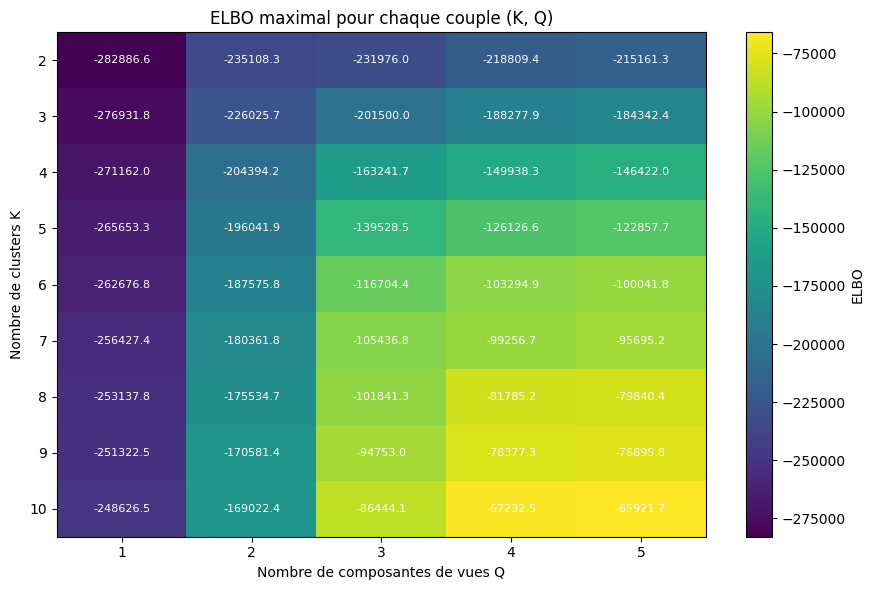

In [12]:
# Conversion en DataFrame
elbo_df = pd.DataFrame(
    [
        {"K": K, "Q": Q, "ELBO": elbo}
        for (K, Q), elbo in elbo_by_kq.items()
    ]
).sort_values(["K", "Q"])

display(elbo_df)

# Tableau croisé K x Q
elbo_matrix = elbo_df.pivot(
    index="K",
    columns="Q",
    values="ELBO"
)

display(elbo_matrix)

# Heatmap
plt.figure(figsize=(9, 6))

plt.imshow(
    elbo_matrix.values,
    aspect="auto",
    cmap="viridis"
)

plt.xticks(
    range(len(elbo_matrix.columns)),
    elbo_matrix.columns
)

plt.yticks(
    range(len(elbo_matrix.index)),
    elbo_matrix.index
)

plt.xlabel("Nombre de composantes de vues Q")
plt.ylabel("Nombre de clusters K")
plt.title("ELBO maximal pour chaque couple (K, Q)")

for i in range(elbo_matrix.shape[0]):
    for j in range(elbo_matrix.shape[1]):
        plt.text(
            j,
            i,
            f"{elbo_matrix.iloc[i, j]:.1f}",
            ha="center",
            va="center",
            color="white",
            fontsize=8
        )

plt.colorbar(label="ELBO")
plt.tight_layout()
plt.show()

In [13]:
elbo_df.sort_values(
    by="ELBO",
    ascending=False
).reset_index(drop=True)

,K,Q,ELBO
0,10,5,-65921.716353
1,10,4,-67232.526712
2,9,5,-76895.797452
3,9,4,-78377.252031
4,8,5,-79840.366246
5,8,4,-81785.180644
6,10,3,-86444.079760
7,9,3,-94753.021222
8,7,5,-95695.192846
9,7,4,-99256.715990


In [14]:
A = np.asarray(A)

N, _, V = A.shape
print(f"Tenseur A : shape = {A.shape}, N = {N}, V = {V}")

Tenseur A : shape = (444, 444, 5), N = 444, V = 5


In [15]:
A = np.asarray(A)

N, _, V = A.shape

# Valeurs à tester
K_values = range(2, 11)   # nombre de clusters d'individus
Q_values = range(1, 6)   # nombre de composantes de vues

N_INIT = 10
results = []

best_model = None
best_node_labels = None
best_layer_labels = None
best_elbo = -np.inf
best_K = None
best_Q = None
best_run = None

for K in K_values:
    for Q in Q_values:
        best_elbo_KQ = -np.inf
        best_model_KQ = None
        best_labels_KQ = None
        best_run_KQ = None

        for run in range(N_INIT):
            model = MimiSBM(
                n_clusters=K,
                n_components=Q,
                clusters_prior="jeffreys",
                components_prior="jeffreys",
                adjacency_prior="jeffreys",
                max_iter=300,
                tol=1e-4,
                random_state=run,
            )

            # fit_predict entraîne le modèle puis retourne les labels
            node_labels, layer_labels = model.fit_predict(A)

            if model.elbo_ > best_elbo_KQ:
                best_elbo_KQ = model.elbo_
                best_model_KQ = model
                best_labels_KQ = (node_labels, layer_labels)
                best_run_KQ = run

        results.append({
            "n_clusters": K,
            "n_components": Q,
            "ELBO": best_elbo_KQ,
            "run": best_run_KQ,
            "converged": best_model_KQ.converged_,
        })

        if best_elbo_KQ > best_elbo:
            best_elbo = best_elbo_KQ
            best_model = best_model_KQ
            best_node_labels, best_layer_labels = best_labels_KQ
            best_K = K
            best_Q = Q
            best_run = best_run_KQ


print("Meilleur modèle selon l'ELBO")
print(f"Nombre optimal de clusters K      : {best_K}")
print(f"Nombre optimal de composantes Q   : {best_Q}")
print(f"ELBO maximal                      : {best_elbo:.2f}")
print(f"Initialisation retenue            : {best_run}")
print(f"Convergence                       : {best_model.converged_}")


Meilleur modèle selon l'ELBO
Nombre optimal de clusters K      : 10
Nombre optimal de composantes Q   : 5
ELBO maximal                      : -65921.72
Initialisation retenue            : 6
Convergence                       : True


In [16]:
# Résultats classés par ELBO décroissant
results_df = (
    pd.DataFrame(results)
    .sort_values("ELBO", ascending=False)
    .reset_index(drop=True)
)

display(results_df)

# Labels finaux
z_pred = best_node_labels   # cluster de chaque individu
w_pred = best_layer_labels  # composante de chaque vue

print(f"Shape des labels individus : {z_pred.shape}")
print(f"Shape des labels vues      : {w_pred.shape}")

,n_clusters,n_components,ELBO,run,converged
0,10,5,-65921.716353,6,True
1,10,4,-67232.526712,6,True
2,9,5,-76895.797452,2,True
3,9,4,-78377.252031,2,True
4,8,5,-79840.366246,7,True
5,8,4,-81785.180644,7,True
6,10,3,-86444.079760,8,True
7,7,5,-95695.192846,7,True
8,9,3,-96277.615672,8,True
9,7,4,-99256.715990,7,True


Shape des labels individus : (444,)
Shape des labels vues      : (5,)
